# 08 — GloFAS à La Clapière (brouillon)

**GloFAS** (Global Flood Awareness System, Copernicus) est un modèle hydrologique (LISFLOOD) qui calcule le débit de toutes les rivières du monde sur une grille de 5 km, à partir de la météo : la météo observée (ERA5) pour le passé, les 51 scénarios de prévision ECMWF pour le futur. Il **n'utilise jamais le débit mesuré** des stations : il ne se recale pas sur la réalité. Open-Meteo le distribue (« Flood API », un débit moyen par jour, en m³/s).

Open-Meteo en donne trois versions (paramètre `models`, vérifié le 2026-10-13 à La Clapière et dans le code d'Open-Meteo) :

| version | ce que c'est | dates disponibles |
|---|---|---|
| `consolidated_v4` : **reconstitution** | le modèle nourri après coup avec la météo observée ; aucune prévision | 1997 → mai 2025 |
| `forecast_v4` : **prévision de la veille** | chaque jour, une prévision sur 30 jours remplace la précédente ; pour un jour passé, il reste celle émise juste avant, donc à environ 1 jour d'avance | juin 2023 → aujourd'hui (+ 30 jours) |
| `seamless_v4` (par défaut) | la reconstitution jusqu'au 31 mai 2023, puis la prévision de la veille | 1997 → aujourd'hui (+ 30 jours) |

Open-Meteo ne garde pas les anciennes prévisions : on ne peut pas savoir ce que GloFAS prévoyait 5 ou 10 jours avant un jour passé (pour cela, il faudrait les archives de Copernicus).

Piège : sur une grille de 5 km, le point le plus proche de la station peut tomber sur un autre cours d'eau. On cherche d'abord, autour de la station, le carreau GloFAS qui ressemble le plus à la Durance mesurée.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

_racine = Path.cwd()
while not (_racine / "src").exists() and _racine != _racine.parent:
    _racine = _racine.parent
if str(_racine) not in sys.path:
    sys.path.insert(0, str(_racine))

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from src import config
from src.station import Station

URL_GLOFAS = "https://flood-api.open-meteo.com/v1/flood"
CACHE_GLOFAS = config.CACHE / "glofas"
CACHE_GLOFAS.mkdir(parents=True, exist_ok=True)

def glofas(lat, lon, debut, fin, modele=None):
    """Débit journalier GloFAS (m³/s) au carreau le plus proche de (lat, lon) ; gardé en cache local.
    modele : None (seamless_v4, par défaut), "consolidated_v4" ou "forecast_v4" (voir le tableau en haut)."""
    f = CACHE_GLOFAS / f"{lat:.3f}_{lon:.3f}_{debut}_{fin}{'_' + modele if modele else ''}.parquet"
    if f.exists():
        return pd.read_parquet(f)["debit"]
    params = dict(latitude=lat, longitude=lon, daily="river_discharge", start_date=debut, end_date=fin)
    if modele:
        params["models"] = modele
    r = requests.get(URL_GLOFAS, params=params, timeout=120)
    r.raise_for_status()
    d = r.json()
    s = pd.Series(d["daily"]["river_discharge"], index=pd.to_datetime(d["daily"]["time"]), name="debit", dtype=float)
    s.attrs = {"lat": d["latitude"], "lon": d["longitude"]}
    s.to_frame().assign(lat_glofas=d["latitude"], lon_glofas=d["longitude"]).to_parquet(f)
    return s

st = Station("X031001001")
print(st, "| mesures depuis", st.debut_donnees.date(), "| position", st.lat, st.lon)

Station(X031001001 : Embrun [La Clapière], Durance) | mesures depuis 2010-04-02 | position 44.55535991 6.49801416


## 1. Débit mesuré : moyennes journalières

GloFAS donne des débits journaliers : on fait la moyenne des débits horaires de chaque jour (UTC), seulement les jours complets.

In [2]:
h = st.mesures(pas="1h")["flow"]
jour = h.groupby(h.index.floor("D")).agg(["mean", "count"])
OBS = jour.loc[jour["count"] == 24, "mean"]
OBS.index = OBS.index.tz_localize(None)
print(f"{len(OBS):,} jours mesurés complets, du {OBS.index.min().date()} au {OBS.index.max().date()} ; débit moyen {OBS.mean():.1f} m³/s")

5,262 jours mesurés complets, du 2010-04-03 au 2026-10-12 ; débit moyen 50.1 m³/s


## 2. Trouver le bon carreau GloFAS

On essaie une grille de points autour de la station (pas de 0,05°, la maille de GloFAS) sur 2019–2020, et on garde **le plus proche de la station parmi ceux dont le débit moyen est comparable** (à ±30 %) : ce sont les carreaux de la Durance elle-même. La corrélation ne départage pas : tous les carreaux, même les petits affluents, suivent la même fonte des neiges. Environ 5 appels par point, une seule fois (cache).

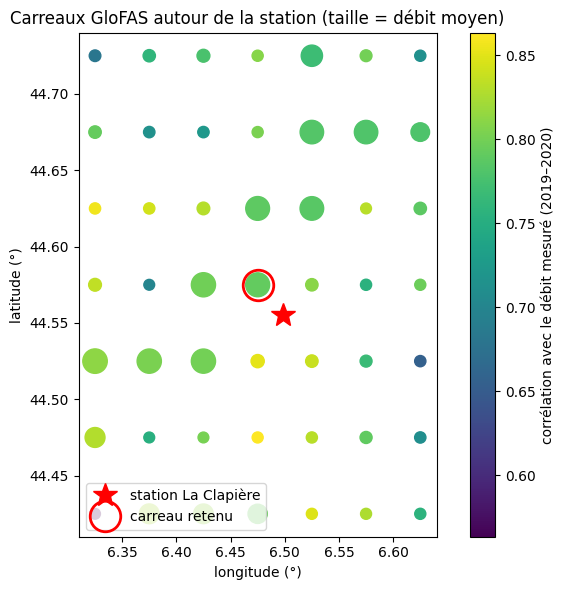

,lat,lon,debit_moyen,rapport,correlation,distance
24,44.575,6.475,41.302,0.870,0.792,0.026
23,44.575,6.425,43.171,0.910,0.798,0.056
16,44.525,6.425,43.418,0.916,0.800,0.060
31,44.625,6.475,40.067,0.843,0.790,0.072
32,44.625,6.525,38.643,0.814,0.785,0.072
15,44.525,6.375,43.875,0.926,0.803,0.093
39,44.675,6.525,37.665,0.793,0.783,0.121
14,44.525,6.325,45.530,0.962,0.812,0.127
3,44.425,6.475,14.489,0.311,0.795,0.131
40,44.675,6.575,37.402,0.787,0.780,0.132


In [3]:
PAS_GRILLE, RAYON = 0.05, 3                      # ± 3 mailles autour de la station
ESSAI = ("2019-01-01", "2020-12-31")
obs_essai = OBS.loc[ESSAI[0]:ESSAI[1]]
lignes, vus = [], set()
for i in range(-RAYON, RAYON + 1):
    for j in range(-RAYON, RAYON + 1):
        lat, lon = st.lat + i * PAS_GRILLE, st.lon + j * PAS_GRILLE
        s = glofas(round(lat, 3), round(lon, 3), *ESSAI)
        f = CACHE_GLOFAS / f"{round(lat, 3):.3f}_{round(lon, 3):.3f}_{ESSAI[0]}_{ESSAI[1]}.parquet"
        lg, og = pd.read_parquet(f)[["lat_glofas", "lon_glofas"]].iloc[0]
        if (lg, og) in vus:
            continue
        vus.add((lg, og))
        commun = obs_essai.index.intersection(s.index)
        lignes.append(dict(lat=lg, lon=og, debit_moyen=s.mean(), rapport=s.loc[commun].mean() / obs_essai.loc[commun].mean(),
                           correlation=np.corrcoef(s.loc[commun], obs_essai.loc[commun])[0, 1]))
cand = pd.DataFrame(lignes).sort_values("correlation", ascending=False)
cand["distance"] = np.hypot(cand["lat"] - st.lat, (cand["lon"] - st.lon) * np.cos(np.radians(st.lat)))
MEILLEUR = cand[cand["rapport"].between(0.7, 1.3)].sort_values("distance").iloc[0]

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(cand["lon"], cand["lat"], c=cand["correlation"], s=40 + 4 * np.sqrt(cand["debit_moyen"]) * 10, cmap="viridis")
ax.plot(st.lon, st.lat, "r*", ms=18, label="station La Clapière")
ax.plot(MEILLEUR["lon"], MEILLEUR["lat"], "o", mfc="none", mec="red", ms=22, mew=2, label="carreau retenu")
fig.colorbar(sc, ax=ax, label="corrélation avec le débit mesuré (2019–2020)")
ax.set_xlabel("longitude (°)"); ax.set_ylabel("latitude (°)"); ax.set_aspect(1 / 0.71)
ax.set_title("Carreaux GloFAS autour de la station (taille = débit moyen)"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
cand[cand["rapport"] > 0.3].sort_values("distance").round(3)

## 3. GloFAS contre le débit mesuré

On compare le débit mesuré à La Clapière (moyenne de chaque jour) aux deux versions de GloFAS, sur le carreau retenu :

- la **reconstitution** : ce que donne GloFAS quand on lui fournit la météo réellement observée. C'est GloFAS dans le meilleur des cas, comme notre modèle quand on l'entraîne avec la météo observée ;
- la **prévision de la veille** : ce que GloFAS annonçait environ un jour avant.

Scores sur les jours où l'on a les deux (mesure et GloFAS) :
- $R^2$ : part des variations du débit mesuré que GloFAS suit (1 = parfait) ;
- NSE (Nash–Sutcliffe, le score habituel des hydrologues) : $1 - \dfrac{\sum_j (Q_\text{GloFAS} - Q_\text{mesuré})^2}{\sum_j (Q_\text{mesuré} - \overline{Q_\text{mesuré}})^2}$ ; 1 = parfait, 0 = pas mieux que de toujours annoncer le débit moyen, négatif = pire ;
- biais : $\overline{Q_\text{GloFAS}} / \overline{Q_\text{mesuré}} - 1$ (−0,2 = GloFAS donne en moyenne 20 % de trop peu).

Pour comparer les deux versions à égalité, on les note aussi sur la seule période où elles existent toutes les deux (juin 2023 → mai 2025).

       réanalyse (→ juillet 2022)  après (prévisions enchaînées)
jours                    3755.000                       1507.000
R²                          0.685                          0.771
NSE                         0.165                          0.512
biais                      -0.218                         -0.347


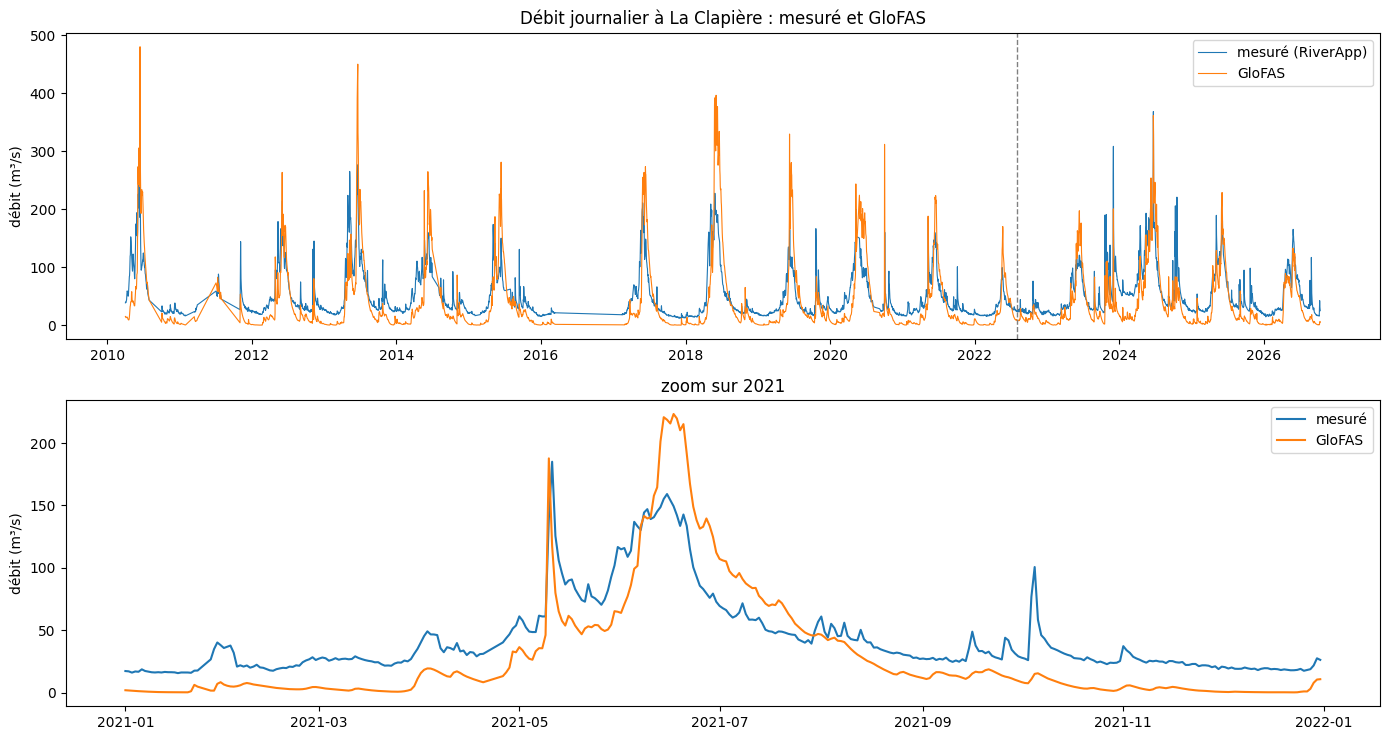

In [4]:
lat, lon = float(MEILLEUR["lat"]), float(MEILLEUR["lon"])
AUJOURDHUI = pd.Timestamp.now().strftime("%Y-%m-%d")
RECONST = glofas(lat, lon, "1997-01-01", AUJOURDHUI, modele="consolidated_v4").dropna()
VEILLE = glofas(lat, lon, "1997-01-01", AUJOURDHUI, modele="forecast_v4").dropna()
COMMUN = RECONST.index.intersection(VEILLE.index)
print(f"reconstitution        : du {RECONST.index.min().date()} au {RECONST.index.max().date()}")
print(f"prévision de la veille : du {VEILLE.index.min().date()} au {VEILLE.index.max().date()}")

def scores(sim):
    jours = OBS.index.intersection(sim.index)
    o, s = OBS.loc[jours], sim.loc[jours]
    return {"période": f"{jours.min():%m/%Y} → {jours.max():%m/%Y}", "jours": len(jours),
            "R²": round(np.corrcoef(o, s)[0, 1] ** 2, 3),
            "NSE": round(1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum(), 3),
            "biais": round(s.mean() / o.mean() - 1, 3)}

pd.DataFrame({"reconstitution (tout)": scores(RECONST),
              "reconstitution (période commune)": scores(RECONST.loc[COMMUN]),
              "prévision de la veille (période commune)": scores(VEILLE.loc[COMMUN]),
              "prévision de la veille (tout)": scores(VEILLE)})

### 3.1 Les séries

En haut, tout depuis 2010 ; en bas, une année où les deux versions existent, pour les voir de près.

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
debut = OBS.index.min()
axes[0].plot(OBS.index, OBS, color="k", lw=0.7, label="mesuré (RiverApp)")
axes[0].plot(RECONST.loc[debut:].index, RECONST.loc[debut:], color="C1", lw=0.7, label="GloFAS reconstitution")
axes[0].plot(VEILLE.index, VEILLE, color="C2", lw=0.7, label="GloFAS prévision de la veille")
axes[0].set_ylabel("débit (m³/s)"); axes[0].legend(loc="upper left")
axes[0].set_title("Débit moyen de chaque jour à La Clapière")
ANNEE = 2024
for serie, couleur, nom in ((OBS, "k", "mesuré"), (RECONST, "C1", "GloFAS reconstitution"), (VEILLE, "C2", "GloFAS prévision de la veille")):
    z = serie.loc[str(ANNEE)]
    axes[1].plot(z.index, z, color=couleur, lw=1.5, label=nom)
axes[1].set_ylabel("débit (m³/s)"); axes[1].set_title(f"Zoom sur {ANNEE}"); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

### 3.2 Où GloFAS se trompe

À gauche, l'**année moyenne** : pour chaque jour de l'année, la moyenne de tous les débits de ce jour depuis 2010 (mesuré et reconstitution, mêmes jours). À droite, chaque jour est un point : débit mesuré en abscisse, débit GloFAS en ordonnée ; sur la diagonale, GloFAS a raison ; échelles logarithmiques pour voir à la fois les basses et les hautes eaux.

In [ ]:
jours = OBS.index.intersection(RECONST.index)
o, s = OBS.loc[jours], RECONST.loc[jours]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.plot(o.groupby(o.index.dayofyear).mean(), color="k", label="mesuré")
a1.plot(s.groupby(s.index.dayofyear).mean(), color="C1", label="GloFAS reconstitution")
a1.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335])
a1.set_xticklabels(["jan", "fév", "mar", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"])
a1.set_ylabel("débit moyen (m³/s)"); a1.set_title(f"Année moyenne ({jours.min().year}-{jours.max().year})"); a1.legend()
a2.scatter(o, s, s=3, alpha=0.2, color="C1")
bornes = [0.5, 600]
a2.plot(bornes, bornes, "k--", lw=1, label="GloFAS = mesuré")
a2.set_xscale("log"); a2.set_yscale("log"); a2.set_xlim(bornes); a2.set_ylim(bornes)
a2.set_xlabel("débit mesuré (m³/s)"); a2.set_ylabel("débit GloFAS (m³/s)"); a2.set_title("Chaque jour : mesuré contre GloFAS"); a2.legend()
plt.tight_layout(); plt.show()

### 3.3 Ce qu'on voit (test du 2026-10-13)

- **Scores** : reconstitution 2010-2025, $R^2$ = 0,68, NSE = 0,25, biais −24 %. GloFAS suit le rythme des saisons, mais ne fait guère mieux que d'annoncer toujours le débit moyen.
- **Prévision de la veille ≈ reconstitution** (NSE 0,44 contre 0,41 sur la même période) : à un jour d'avance, la météo prévue vaut presque la météo observée ; ses erreurs viennent du modèle hydrologique, pas de la météo.
- **Les basses eaux sont très fausses** : de novembre à mars, GloFAS donne 2 à 5 m³/s quand on mesure 20 à 25 m³/s. Sur le nuage de points, sous 30 m³/s mesurés, GloFAS donne n'importe quoi entre 0,5 et 20 : il ne reproduit pas ce débit d'hiver soutenu (la cause n'est pas vérifiée ici).
- **La fonte des neiges arrive trop tard puis trop fort** : en avril-mai, la Durance monte bien avant GloFAS ; en juin, GloFAS monte à 215 m³/s en moyenne contre 140 mesurés.
- **Les crues d'automne sont vues mais sous-estimées** (octobre 2024 : 220 m³/s mesurés, 120 pour GloFAS).
- **Prévision du jour** : GloFAS part d'environ 5 m³/s pour 25 mesurés ; l'erreur est déjà là au départ, avant toute prévision.
- **Échéance** : Open-Meteo ne garde pas les anciennes prévisions, on ne peut donc pas noter GloFAS à 5 ou 10 jours d'avance avec ces données.


## 4. La prévision GloFAS du moment : 51 scénarios

GloFAS fait tourner son modèle sur chacun des 51 scénarios météo de l'ECMWF (1 de contrôle, sans perturbation, et 50 légèrement perturbés), sur 30 jours. On trace la dernière prévision quotidienne disponible :

- à droite du trait vertical (aujourd'hui) : la prévision, un trait fin par scénario, le contrôle en pointillés, la médiane en gras ;
- à gauche : pour chaque jour passé, ce que donnait la prévision émise juste avant (comme la « prévision de la veille » de la section 3), avec le débit mesuré en noir pour comparer.

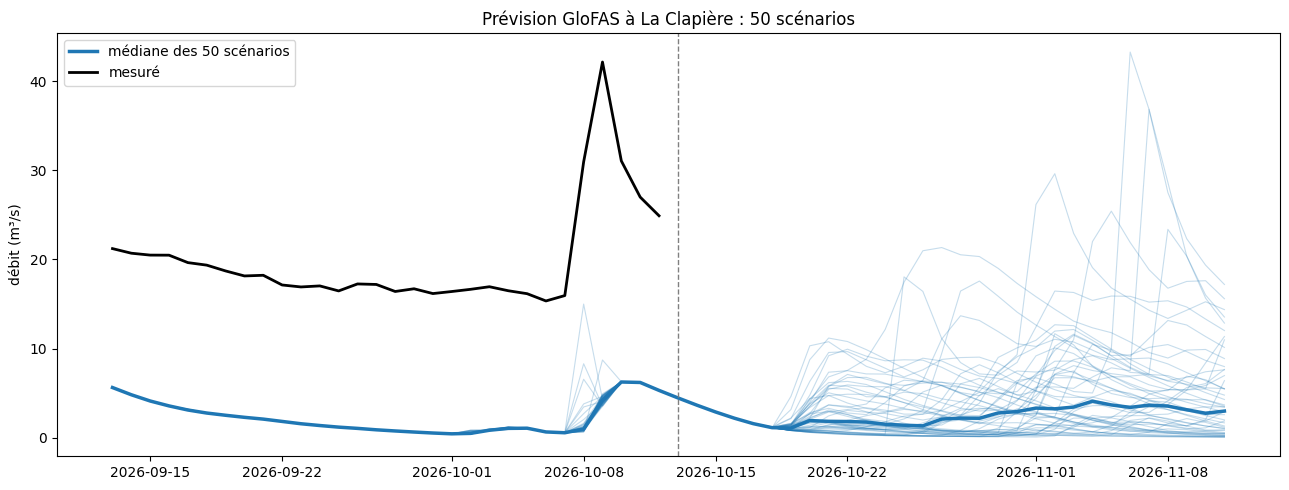

In [5]:
r = requests.get(URL_GLOFAS, params=dict(latitude=lat, longitude=lon, daily="river_discharge",
                                         forecast_days=30, past_days=30, ensemble="true"), timeout=120)
d = pd.DataFrame(r.json()["daily"]).set_index("time"); d.index = pd.to_datetime(d.index)
membres = d[[c for c in d.columns if "member" in c]]
controle = d["river_discharge"]                       # le scénario de contrôle (membre 0)
aujourdhui = pd.Timestamp.now().normalize()
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(membres.index, membres, color="C0", alpha=0.2, lw=0.8)
ax.plot(membres.index, membres.median(axis=1), color="C0", lw=2.5, label=f"médiane des {membres.shape[1]} scénarios perturbés")
ax.plot(controle.index, controle, color="C0", ls="--", lw=1.5, label="scénario de contrôle")
recent = OBS.loc[OBS.index >= membres.index.min()]
ax.plot(recent.index, recent, "k", lw=2, label="mesuré")
ax.axvline(aujourdhui, color="grey", ls="--", lw=1)
ax.text(aujourdhui, ax.get_ylim()[1] * 0.95, "  aujourd'hui", color="grey", va="top")
ax.set_ylabel("débit moyen du jour (m³/s)"); ax.legend(loc="upper left")
ax.set_title(f"GloFAS à La Clapière : 30 jours passés et prévision sur 30 jours (lue le {aujourdhui:%d/%m/%Y})")
plt.tight_layout(); plt.show()